`Practice 8,Assignment 4 Variant 16: Coffee shop loyalty`

# 1. Imports and reproducibility

In [ ]:
# References: [1][2][3][4] (full list at the end of the notebook)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score)

rng = np.random.default_rng(42)

# 2. Generate the synthetic customers
1,000 customers. The assumptions behind the hidden rule: frequent visitors tend to come back, slightly higher order prices go with committed customers, and long waits hurt.

In [ ]:
# References: [2][13][16] (full list at the end of the notebook)
n = 1000
df = pd.DataFrame({
    "visits_per_week": np.clip(rng.gamma(4.0, 0.7, n), 0.2, 7.0).round(1),
    "order_price": np.clip(rng.normal(6.5, 2.0, n), 2.0, 15.0).round(2),
    "wait_time": np.clip(rng.gamma(3.0, 1.6, n), 0.5, 20.0).round(1),
})

z = (0.25
     + 0.90 * (df["visits_per_week"] - 2.8)
     + 0.12 * (df["order_price"] - 6.5)
     - 0.22 * (df["wait_time"] - 4.8)
     - 0.15 * np.maximum(df["wait_time"] - 10, 0))
prob = 1 / (1 + np.exp(-z))
df["returns_next_week"] = (rng.random(n) < prob).astype(int)

print(df.shape)
print(df.head())

(1000, 4)
   visits_per_week  order_price  wait_time  returns_next_week
0              3.0         6.32       13.7                  0
1              3.7         5.44        3.5                  0
2              2.7        10.93        6.3                  1
3              2.5         5.60        1.4                  1
4              3.9         5.17        3.2                  1


# 3. Introduce and document missing readings
Real systems lose data, so I simulate it: the till fails to store the order price for 50 customers (5 %) and the queue timer fails to log the wait time for 80 customers (8 %)

In [ ]:
# References: [3] (full list at the end of the notebook)
for column, k in [("order_price", 50), ("wait_time", 80)]:
    missing_idx = rng.choice(n, size=k, replace=False)
    df.loc[missing_idx, column] = np.nan

print("Missing values per column:")
print(df.isna().sum())
print()
print("Class counts (0 = does not return, 1 = returns):")
print(df["returns_next_week"].value_counts())
print()
print("Class proportions:")
print(df["returns_next_week"].value_counts(normalize=True).round(3))
print()
print(df.describe().round(2))

Missing values per column:
visits_per_week       0
order_price          50
wait_time            80
returns_next_week     0
dtype: int64

Class counts (0 = does not return, 1 = returns):
returns_next_week
1    544
0    456
Name: count, dtype: int64

Class proportions:
returns_next_week
1    0.544
0    0.456
Name: proportion, dtype: float64

       visits_per_week  order_price  wait_time  returns_next_week
count          1000.00       950.00     920.00            1000.00
mean              2.75         6.58       4.79               0.54
std               1.34         1.99       2.70               0.50
min               0.30         2.00       0.50               0.00
25%               1.80         5.21       2.80               0.00
50%               2.60         6.56       4.30               1.00
75%               3.50         7.95       6.10               1.00
max               7.00        12.62      19.80               1.00


# 4. Visualise the features

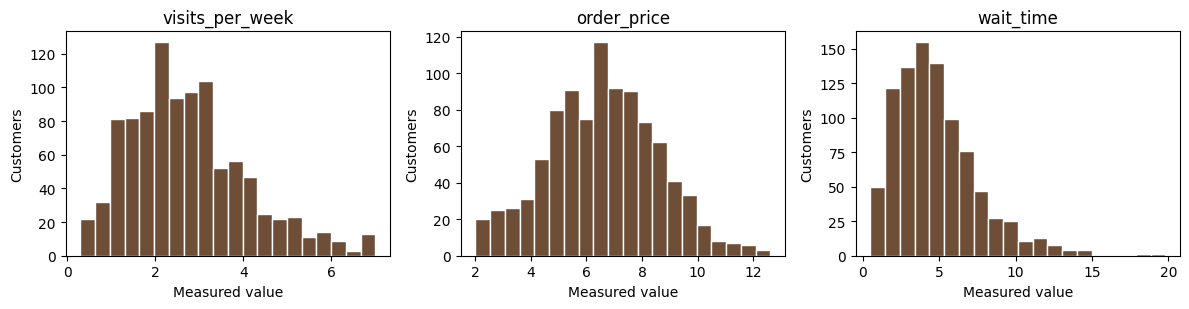

In [ ]:
# References: [4] (full list at the end of the notebook)
features = ["visits_per_week", "order_price", "wait_time"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, features):
    ax.hist(df[col].dropna(), bins=20, color="#6F4E37", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Measured value")
    ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

                   visits_per_week  order_price  wait_time
returns_next_week                                         
0                             2.19         6.50       5.49
1                             3.21         6.65       4.22


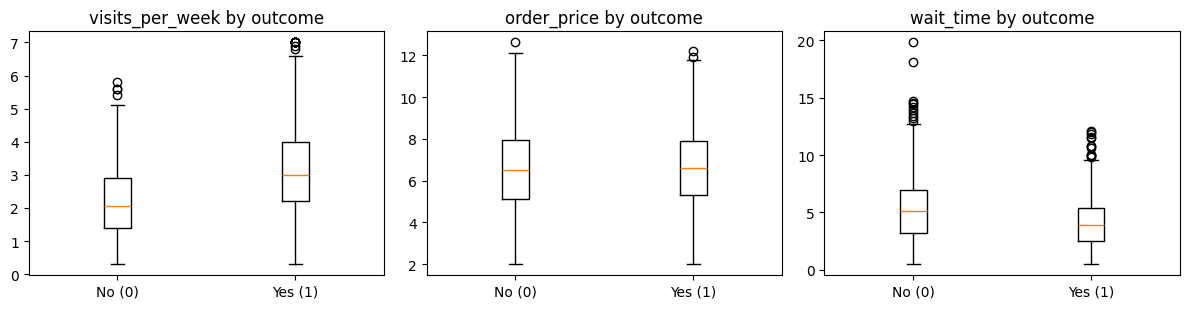

In [ ]:
# References: [4][3] (full list at the end of the notebook)
print(df.groupby("returns_next_week")[features].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, features):
    data = [df.loc[df["returns_next_week"] == c, col].dropna() for c in (0, 1)]
    ax.boxplot(data)
    ax.set_xticklabels(["No (0)", "Yes (1)"])
    ax.set_title(col + " by outcome")
plt.tight_layout()
plt.show()

# 5. Separate X / y and split BEFORE any preprocessing
80 % train (800 rows) / 20 % test (200 rows), stratified so both parts keep about the same share of returners (54.4 % vs 54.5 %). The imputer and scaler will be fitted on training rows only, inside the Pipeline.

In [ ]:
# References: [5][13] (full list at the end of the notebook)
X = df[features]
y = df["returns_next_week"]
print("Features:", X.shape, "| Target:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Share of returners  train:", round(y_train.mean(), 3),
      " test:", round(y_test.mean(), 3))

Features: (1000, 3) | Target: (1000,)
Train: (800, 3) Test: (200, 3)
Share of returners  train: 0.544  test: 0.545


# 6. Logistic Regression Pipeline (imputer → scaler → classifier)

In [ ]:
# References: [6][7][8][9] (full list at the end of the notebook)
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
model.fit(X_train, y_train)

test_labels = model.predict(X_test)
test_risks = model.predict_proba(X_test)[:, 1]
print("First labels:", test_labels[:8])
print("First probabilities:", np.round(test_risks[:8], 3))

First labels: [1 1 1 1 1 1 0 1]
First probabilities: [0.509 0.727 0.531 0.693 0.583 0.663 0.497 0.545]


# 8. Confusion matrix and metrics (Logistic Regression, test set)

Confusion matrix (rows = actual, columns = predicted):
[[49 42]
 [25 84]]
TN=49  FP=42  FN=25  TP=84


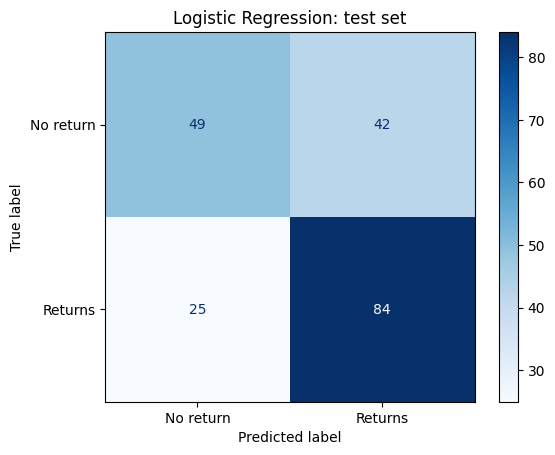

              precision    recall  f1-score   support

           0       0.66      0.54      0.59        91
           1       0.67      0.77      0.71       109

    accuracy                           0.67       200
   macro avg       0.66      0.65      0.65       200
weighted avg       0.66      0.67      0.66       200

ROC-AUC: 0.78


In [ ]:
# References: [10] (full list at the end of the notebook)
cm = confusion_matrix(y_test, test_labels, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

ConfusionMatrixDisplay(cm, display_labels=["No return", "Returns"]).plot(cmap="Blues")
plt.title("Logistic Regression: test set")
plt.show()

print(classification_report(y_test, test_labels, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, test_risks), 3))

# 8. Stratified 3-fold cross-validation (training data only)

In [ ]:
# References: [11] (full list at the end of the notebook)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
print("Logistic fold F1:", np.round(scores, 3))
print("Mean F1:", round(scores.mean(), 3), "| Std F1:", round(scores.std(), 3))

Logistic fold F1: [0.72  0.657 0.708]
Mean F1: 0.695 | Std F1: 0.027


# 9. Logistic Regression coefficients

wait_time         -0.540
order_price        0.108
visits_per_week    0.898
dtype: float64


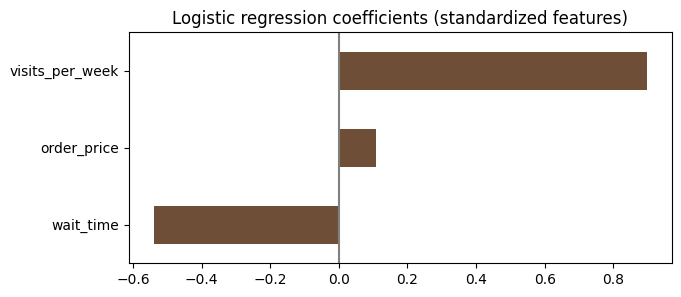

In [ ]:
# References: [9] (full list at the end of the notebook)
weights = model.named_steps["classifier"].coef_[0]
coefs = pd.Series(weights, index=X.columns).sort_values()
print(coefs.round(3))
coefs.plot(kind="barh", figsize=(7, 3), color="#6F4E37")
plt.axvline(0, color="gray")
plt.title("Logistic regression coefficients (standardized features)")
plt.show()

# 10. Random Forest Pipeline

In [ ]:
# References: [14][15] (full list at the end of the notebook)
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=150, max_depth=6,
        min_samples_leaf=3, random_state=42,
        n_jobs=-1))
])
rf_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(max_depth=6, min_samples_leaf=3,
                                        n_estimators=150, n_jobs=-1,
                                        random_state=42))])

# 11. Fair comparison with the same folds and F1 metric

Logistic fold F1: [0.72  0.657 0.708]
Forest   fold F1: [0.704 0.664 0.711]
Logistic mean F1: 0.695 | SD: 0.027
Forest   mean F1: 0.693 | SD: 0.02


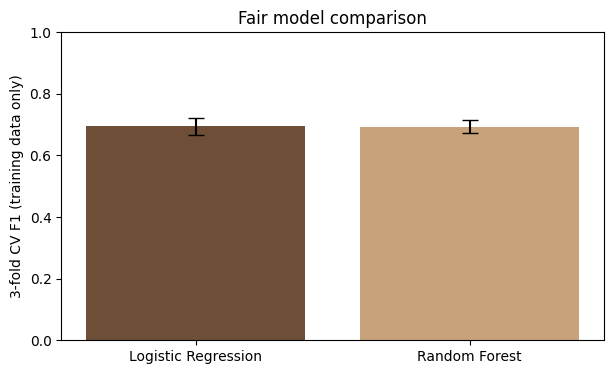

In [ ]:
# References: [11] (full list at the end of the notebook)
lr_cv = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
rf_cv = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring="f1")

print("Logistic fold F1:", np.round(lr_cv, 3))
print("Forest   fold F1:", np.round(rf_cv, 3))
print("Logistic mean F1:", lr_cv.mean().round(3), "| SD:", lr_cv.std().round(3))
print("Forest   mean F1:", rf_cv.mean().round(3), "| SD:", rf_cv.std().round(3))

names = ["Logistic Regression", "Random Forest"]
means = [lr_cv.mean(), rf_cv.mean()]
stds = [lr_cv.std(), rf_cv.std()]
plt.figure(figsize=(7, 4))
plt.bar(names, means, yerr=stds, capsize=6, color=["#6F4E37", "#C8A27A"])
plt.ylim(0, 1)
plt.ylabel("3-fold CV F1 (training data only)")
plt.title("Fair model comparison")
plt.show()

# 12 CV F1, then test ONCE on the untouched test set

Selected: Logistic Regression
              precision    recall  f1-score   support

           0       0.66      0.54      0.59        91
           1       0.67      0.77      0.71       109

    accuracy                           0.67       200
   macro avg       0.66      0.65      0.65       200
weighted avg       0.66      0.67      0.66       200

ROC-AUC: 0.78
Final confusion matrix:
[[49 42]
 [25 84]]
TN=49  FP=42  FN=25  TP=84


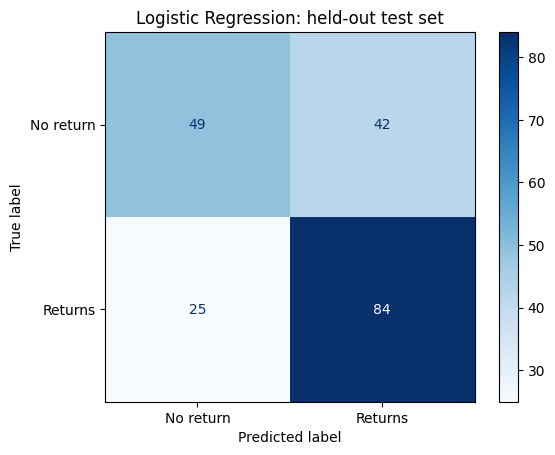

In [ ]:
# References: [10][13] (full list at the end of the notebook)
best_model = rf_model if rf_cv.mean() > lr_cv.mean() else model
best_name = "Random Forest" if best_model is rf_model else "Logistic Regression"

best_model.fit(X_train, y_train)
final_pred = best_model.predict(X_test)
final_prob = best_model.predict_proba(X_test)[:, 1]

print("Selected:", best_name)
print(classification_report(y_test, final_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, final_prob), 3))

cm_final = confusion_matrix(y_test, final_pred, labels=[0, 1])
print("Final confusion matrix:")
print(cm_final)
tn, fp, fn, tp = cm_final.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
ConfusionMatrixDisplay(cm_final, display_labels=["No return", "Returns"]).plot(cmap="Blues")
plt.title(best_name + ": held-out test set")
plt.show()

# 13 Random Forest feature importance

order_price        0.207
wait_time          0.319
visits_per_week    0.474
dtype: float64


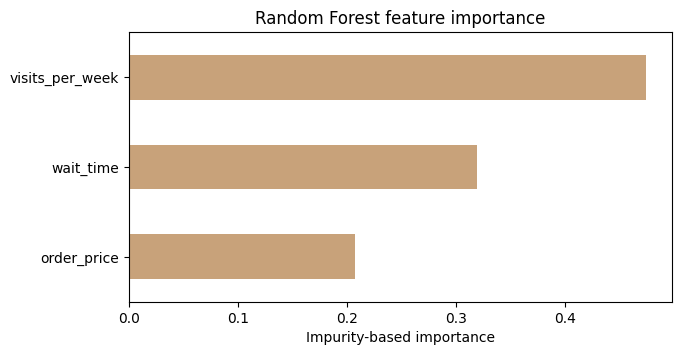

In [ ]:
# References: [14][15] (full list at the end of the notebook)
rf_model.fit(X_train, y_train)
rf_importance = pd.Series(
    rf_model.named_steps["classifier"].feature_importances_,
    index=X_train.columns).sort_values()
print(rf_importance.round(3))
rf_importance.plot(kind="barh", figsize=(7, 3.5), color="#C8A27A")
plt.xlabel("Impurity-based importance")
plt.title("Random Forest feature importance")
plt.show()

# 14. Predict a new customer

In [ ]:
# References: [9] (full list at the end of the notebook)
new_customer = pd.DataFrame([{
    "visits_per_week": 1.5,
    "order_price": 5.0,
    "wait_time": np.nan
}])
p_return = best_model.predict_proba(new_customer)[0, 1]
print(f"Selected model: {best_name}")
print(f"Estimated probability of returning next week: {p_return:.1%}")
print("Label at threshold 0.50:", int(p_return >= 0.5))

Selected model: Logistic Regression
Estimated probability of returning next week: 35.7%
Label at threshold 0.50: 0


# 16. Decision threshold and cost of errors

Break-even: send a coupon when P(returns) < 0.33
Threshold with the highest training value: 0.35
No coupons                               net value = $    0.00
Threshold 0.50                           net value = $   -0.50
Threshold 0.35 (from training CV)        net value = $    5.50
Coupon for everyone                      net value = $  -63.50


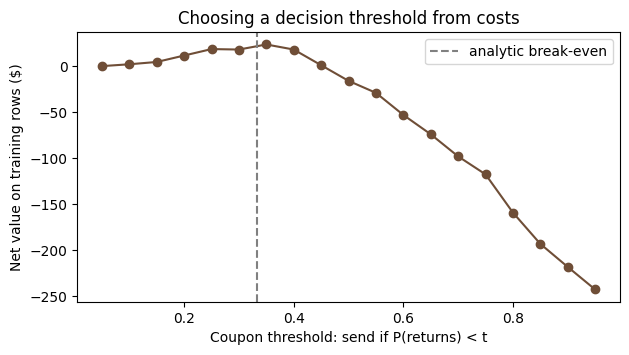

In [ ]:
# References: [13][12] (full list at the end of the notebook)
coupon_cost = 1.00
margin_if_kept = 5.00
save_prob = 0.30
gain_if_leaver = save_prob * margin_if_kept
breakeven = 1 - coupon_cost / gain_if_leaver
print(f"Break-even: send a coupon when P(returns) < {breakeven:.2f}")

def net_value(y_true, p_return, t):
    send = p_return < t
    return float(send.sum() * -coupon_cost
                 + (send & (np.asarray(y_true) == 0)).sum() * gain_if_leaver)

oof = cross_val_predict(best_model, X_train, y_train, cv=cv,
                        method="predict_proba")[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
train_values = [net_value(y_train, oof, t) for t in grid]
best_t = grid[int(np.argmax(train_values))]
print("Threshold with the highest training value:", best_t)

for label, t in [("No coupons", 0.0), ("Threshold 0.50", 0.5),
                 (f"Threshold {best_t:.2f} (from training CV)", best_t),
                 ("Coupon for everyone", 1.01)]:
    print(f"{label:<40s} net value = ${net_value(y_test, final_prob, t):8.2f}")

plt.figure(figsize=(7, 3.5))
plt.plot(grid, train_values, marker="o", color="#6F4E37")
plt.axvline(breakeven, color="gray", linestyle="--", label="analytic break-even")
plt.xlabel("Coupon threshold: send if P(returns) < t")
plt.ylabel("Net value on training rows ($)")
plt.title("Choosing a decision threshold from costs")
plt.legend()
plt.show()

## References
[1] Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825-2830.
[2] Harris, C. R. et al. (2020). Array programming with NumPy. Nature, 585, 357-362. Random Generator: https://numpy.org/doc/stable/reference/random/generator.html
[3] pandas documentation: https://pandas.pydata.org/docs/
[4] Matplotlib documentation: https://matplotlib.org/stable/
[5] train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
[6] Pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
[7] SimpleImputer: https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
[8] StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
[9] LogisticRegression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
[10] Metrics (confusion_matrix, classification_report, roc_auc_score): https://scikit-learn.org/stable/modules/model_evaluation.html
[11] StratifiedKFold and cross_val_score: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html , https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
[12] cross_val_predict: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html
[13] Course lecture "Rational Decisions and Classical Machine Learning" (AI Fundamentals): train/test split, data leakage, evaluation metrics, decisions from expected cost.
[14] RandomForestClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
[15] Breiman, L. (2001). Random Forests. Machine Learning, 45(1), 5-32.
[16] UCI Machine Learning Repository, Online Retail (id=352): https://archive.ics.uci.edu/dataset/352/online+retail (suggested starting point; not used because it has no wait-time feature).